# Notebook setup

Setup Qt for interactive viewing in this notebook

In [1]:
%gui qt

Define the locations of source data and results

In [2]:
DATAPATH = "C:\\Users\\md1spsx\\Documents\\Data\\case_studies\\source\\lung_dce"
BUILD_PATH = "C:\\Users\\md1spsx\\Documents\\Data\\case_studies\\results\\lung_dce"

import os

IMAGEPATH = os.path.join(BUILD_PATH, 'images')
CHECKPOINTSPATH = os.path.join(BUILD_PATH, 'checkpoints')
os.makedirs(IMAGEPATH, exist_ok=True)
os.makedirs(CHECKPOINTSPATH, exist_ok=True)

resultspath = os.path.join(BUILD_PATH, 'dicom')
SUBJ = 'SheffieldSubject'
DATA = [resultspath, SUBJ, 'Data']
MAPS = [resultspath, SUBJ, 'Maps']
MASKS = [resultspath, SUBJ, 'Masks']

# Step 1: Data cleaning

Harmonize the DICOM data, saving the results in the build folder

In [3]:
from case_studies.lung_dce import harmonize_data

harmonize_data(DATAPATH, DATA)

c:\Users\md1spsx\Documents\GitHub\case-studies\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Reading DICOM folder: 0it [00:00, ?it/s]
Copying series ['geservice', ('POLARIS_STH21860', 0), ('PERFUSION (flip 2)_copy', 1)]: 100%|██████████| 60/60 [00:00<00:00, 142.53it/s]
Sorting series..: 100%|██████████| 60/60 [00:00<00:00, 859.95it/s]
Writing values..: 60it [00:00, 93.39it/s] 
Copying series ['SheffieldSubject', 'Data', '3D-VFA']: 100%|██████████| 60/60 [00:00<00:00, 143.33it/s]
Copying series ['geservice', ('POLARIS_STH21860', 0), ('PERFUSION (flip 4)_copy', 0)]: 100%|██████████| 60/60 [00:00<00:00, 73.69it/s]
Sorting series..: 100%|██████████| 60/60 [00:00<00:00, 497.19it/s]
Writing values..: 60it [00:00, 104.28it/s]
Copying series ['SheffieldSubject', 'Data', '3D-VFA']: 100%|██████████| 60/60 [00:00<00:

Finished harmonizing data. VFA and DCE series are now merged into single series for analysis.


Inspect the 4D source data

In [5]:
from case_studies.lung_dce import view_dce_notebook

view_dce_notebook(DATA)

Reading volume..: 100%|██████████| 1152/1152 [00:01<00:00, 612.15it/s]


# Step 2: Image segmentation

Compute some descriptive maps that can be used as a basis for segmentation

In [6]:
from case_studies.lung_dce import compute_descriptive_maps

compute_descriptive_maps(DATA, MAPS)

Reading volume..: 100%|██████████| 1152/1152 [00:01<00:00, 637.55it/s]
Writing volume..: 24it [00:00, 151.72it/s]
Writing volume..: 24it [00:00, 187.01it/s]
Writing volume..: 24it [00:00, 160.09it/s]
Writing volume..: 24it [00:00, 166.44it/s]
Writing volume..: 24it [00:00, 163.71it/s]

Finished computing descriptive maps. Maps are saved in the MAPS series.


Autosegment the lungs using TotalSegmentator

In [7]:
from case_studies.lung_dce import autosegment_lungs

autosegment_lungs(MAPS, MASKS)

Reading volume..: 100%|██████████| 24/24 [00:00<00:00, 602.05it/s]


Saving source as nifti..
Segmenting organs..

If you use this tool please cite: https://pubs.rsna.org/doi/10.1148/ryai.230024

Resampling...
  Resampled in 0.55s
Predicting part 1 of 2 ...


100%|██████████| 18/18 [00:59<00:00,  3.31s/it]


Predicting part 2 of 2 ...


100%|██████████| 18/18 [01:01<00:00,  3.44s/it]


  Predicted in 145.59s
Resampling...
  Resampled in 0.08s
Saving segmentations...
  Saved in 7.01s


Reading results..: 100%|██████████| 50/50 [00:00<00:00, 52.18it/s]
Writing volume..: 24it [00:00, 169.55it/s]
Writing volume..: 24it [00:00, 169.54it/s]
Writing volume..: 24it [00:00, 173.96it/s]

Finished automatic segmentation of lungs. Masks are saved in the MASKS series.


Check the masks and edit interactively, if needed

In [8]:
from case_studies.lung_dce import edit_autosegmented_lungs_notebook

edit_autosegmented_lungs_notebook(MAPS, MASKS)

Reading volume..: 100%|██████████| 24/24 [00:00<00:00, 490.00it/s]
Writing volume..: 24it [00:00, 177.61it/s]
Reading volume..: 100%|██████████| 24/24 [00:00<00:00, 611.77it/s]
Writing volume..: 24it [00:00, 171.57it/s]

Finished editing lung segmentations. Edited masks are saved in the MASKS series.


Draw the region of interest for the arterial input function

In [9]:
from case_studies.lung_dce import draw_arterial_inputs_notebook

draw_arterial_inputs_notebook(MAPS, MASKS)

Reading volume..: 100%|██████████| 24/24 [00:00<00:00, 532.48it/s]
Writing volume..: 24it [00:00, 168.96it/s]


# Step 3: Breathing motion correction

Motion-correct the VFA data for signal calibration

In [10]:
from case_studies.lung_dce import vfa_motion_correction

vfa_motion_correction(DATA, MAPS)

Reading volume..: 100%|██████████| 240/240 [00:00<00:00, 637.32it/s]


Initializing..
Iteration 1: fitting signal model


Fitting VFA model: 100%|██████████| 3932160/3932160 [01:14<00:00, 53079.09it/s]
c:\Users\md1spsx\Documents\GitHub\case-studies\.venv\Lib\site-packages\mdreg\fit_models.py:918: RuntimeWarning: divide by zero encountered in divide
  E = 1/A


Iteration 1: fitting deformation fields
Calculation time for iteration 1: 1.6089847683906555 min
Iteration 2: fitting signal model


Fitting VFA model: 100%|██████████| 3932160/3932160 [01:16<00:00, 51717.03it/s]


...

Fitting VFA model: 100%|██████████| 3932160/3932160 [01:16<00:00, 51499.05it/s]


Iteration 4: fitting deformation fields
Calculation time for iteration 4: 1.6448047876358032 min
Iteration 5: fitting signal model


Fitting VFA model: 100%|██████████| 3932160/3932160 [01:16<00:00, 51207.78it/s]


Iteration 5: fitting deformation fields
Calculation time for iteration 5: 1.6691135048866272 min
Total calculation time: 8.188389507929484 min


Writing volume..: 100%|██████████| 4/4 [00:01<00:00,  2.45it/s]


Check the motion-corrected VFA data

In [ ]:
from case_studies.lung_dce import view_vfa_notebook

view_vfa_notebook(MAPS)

Perform DCE motion correction

*Note* this is actually a dummy function for this demo which just creates a copy. Motion correction takes a long time and these breath hold data don't need it, so in this case it can be safely skipped.

In [ ]:
from case_studies.lung_dce import dce_motion_correction

dce_motion_correction(DATA, MAPS)

# Step 4: Signal calibration

Fit the VFA data to derive T1 and S0 maps

In [ ]:
from case_studies.lung_dce import vfa_fit

vfa_fit(MAPS)

Align VFA and DCE data, computing also proper scaling factors for the signal intensities.

In [ ]:
from case_studies.lung_dce import align_vfa_with_dce

align_vfa_with_dce(MAPS, MASKS)

# Step 5: Parameter reconstruction

Now we have everything in place to model the data and derive the parameters of interest.

Model-based whole-lung analysis

In [ ]:
from case_studies.lung_dce import roi_analysis_model_based

roi_analysis_model_based(MAPS, MASKS, IMAGEPATH)

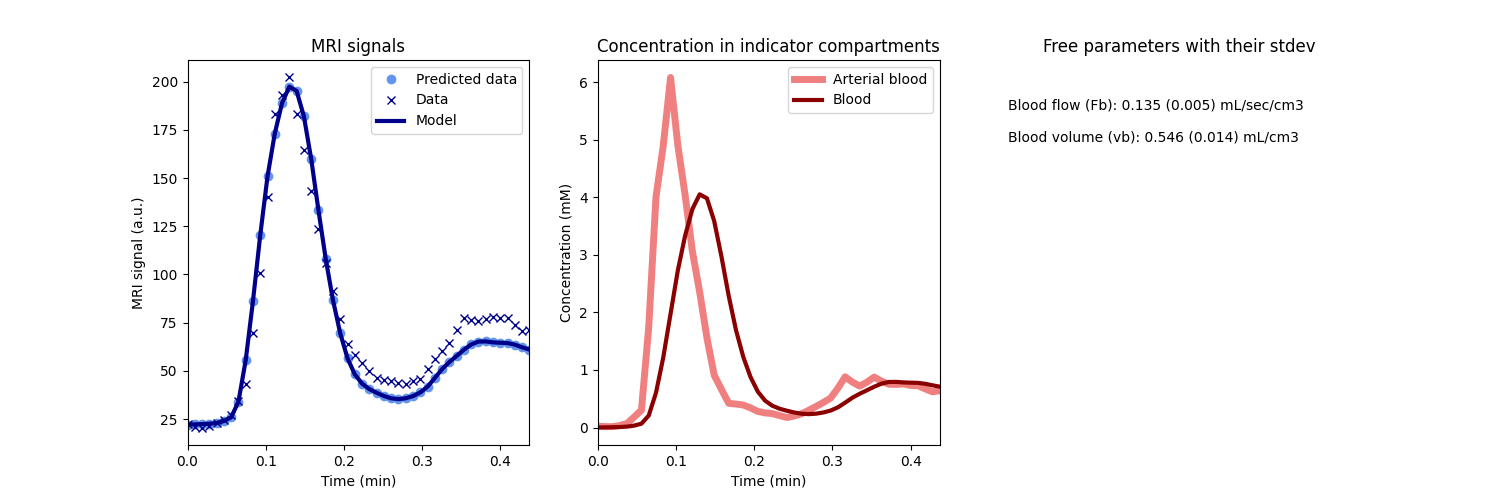

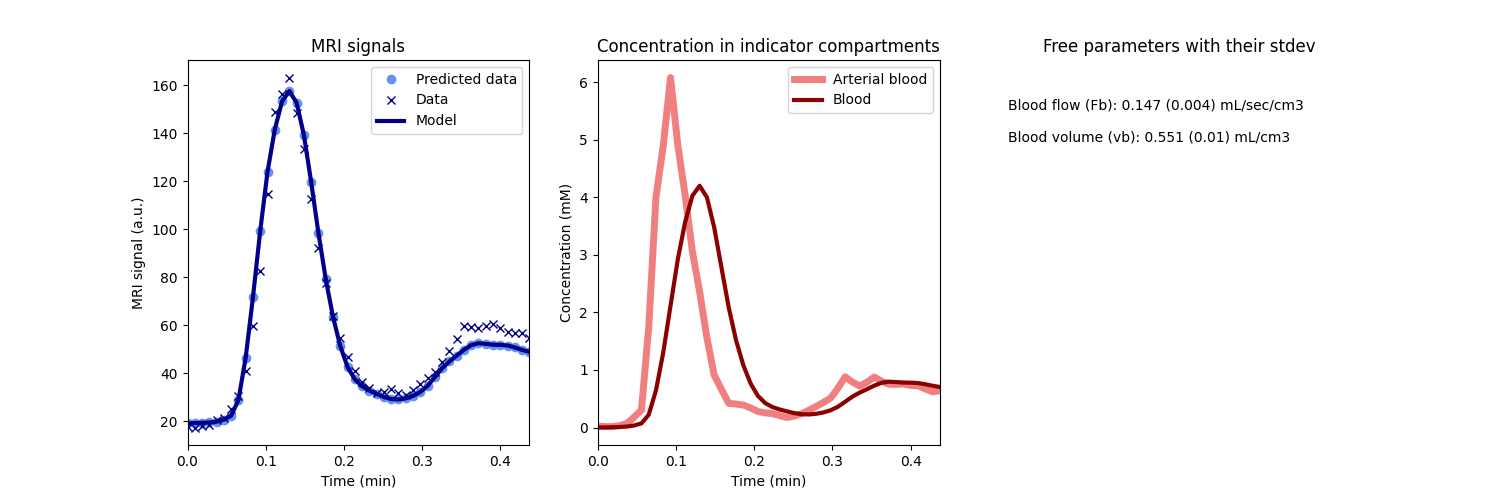

In [7]:
from case_studies.lung_dce import view_png

png = os.path.join(IMAGEPATH, f'model_based_lung_left_edited.png')
view_png(png)
png = os.path.join(IMAGEPATH, f'model_based_lung_right_edited.png')
view_png(png)

Model-free whole-lung analysis

In [ ]:
from case_studies.lung_dce import roi_analysis_model_free

roi_analysis_model_free(MAPS, MASKS, IMAGEPATH)

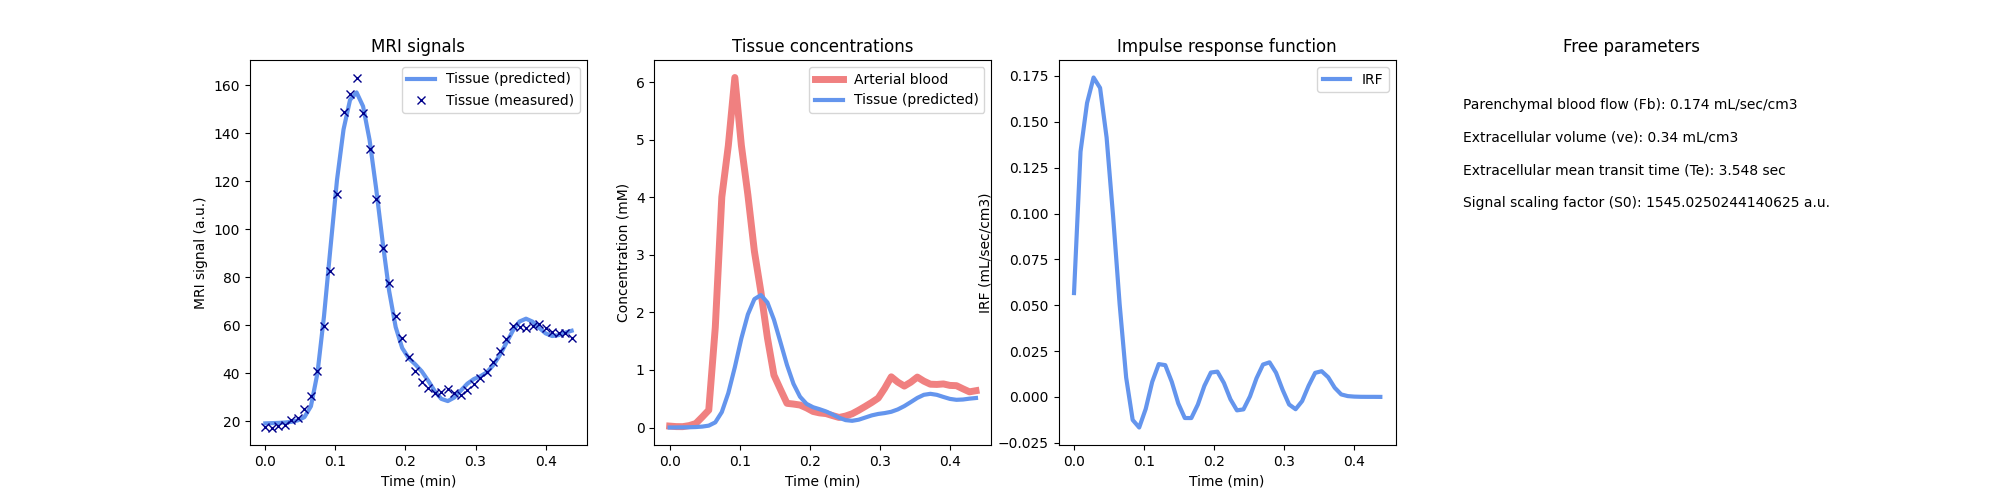

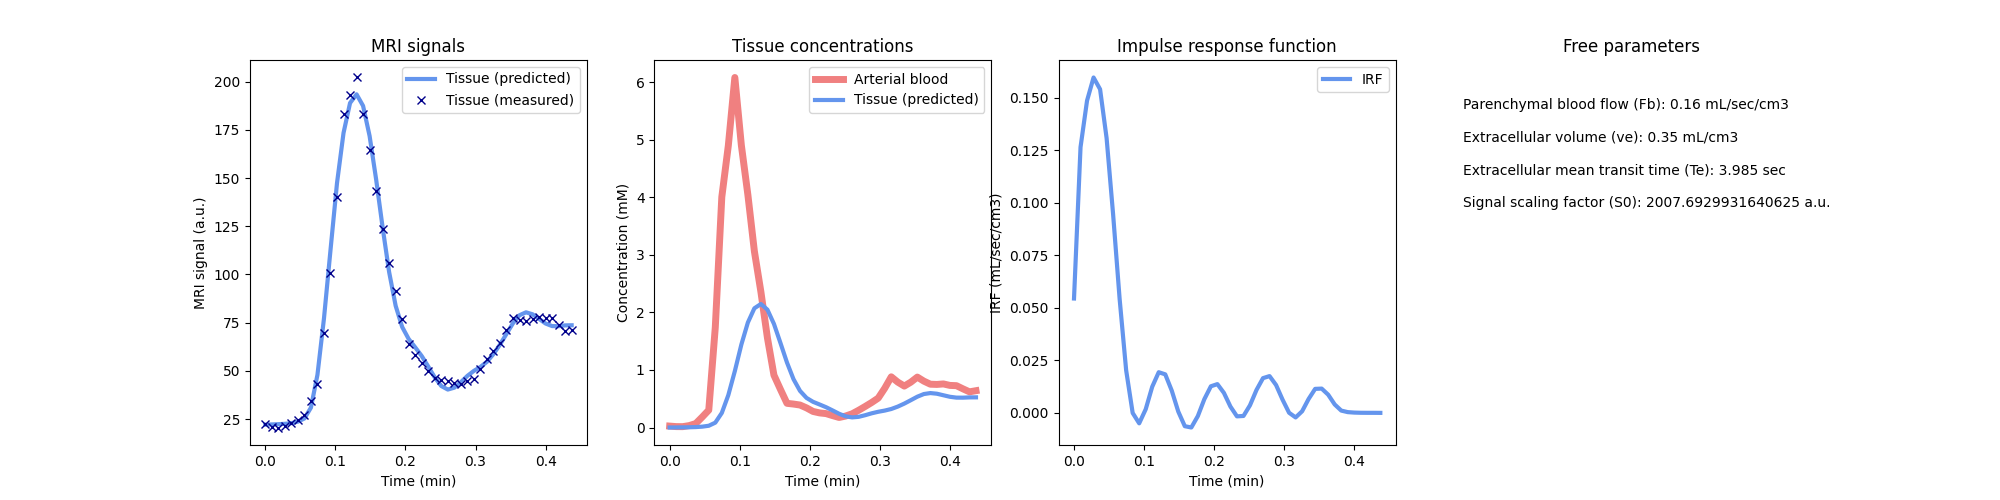

In [9]:
from case_studies.lung_dce import view_png

png = os.path.join(IMAGEPATH, f'model_free_lung_right_edited.png')
view_png(png)
png = os.path.join(IMAGEPATH, f'model_free_lung_left_edited.png')
view_png(png)

Pixel-by-pixel model-free analysis

In [ ]:
from case_studies.lung_dce import pixel_analysis_model_free

pixel_analysis_model_free(MAPS, MASKS, IMAGEPATH)

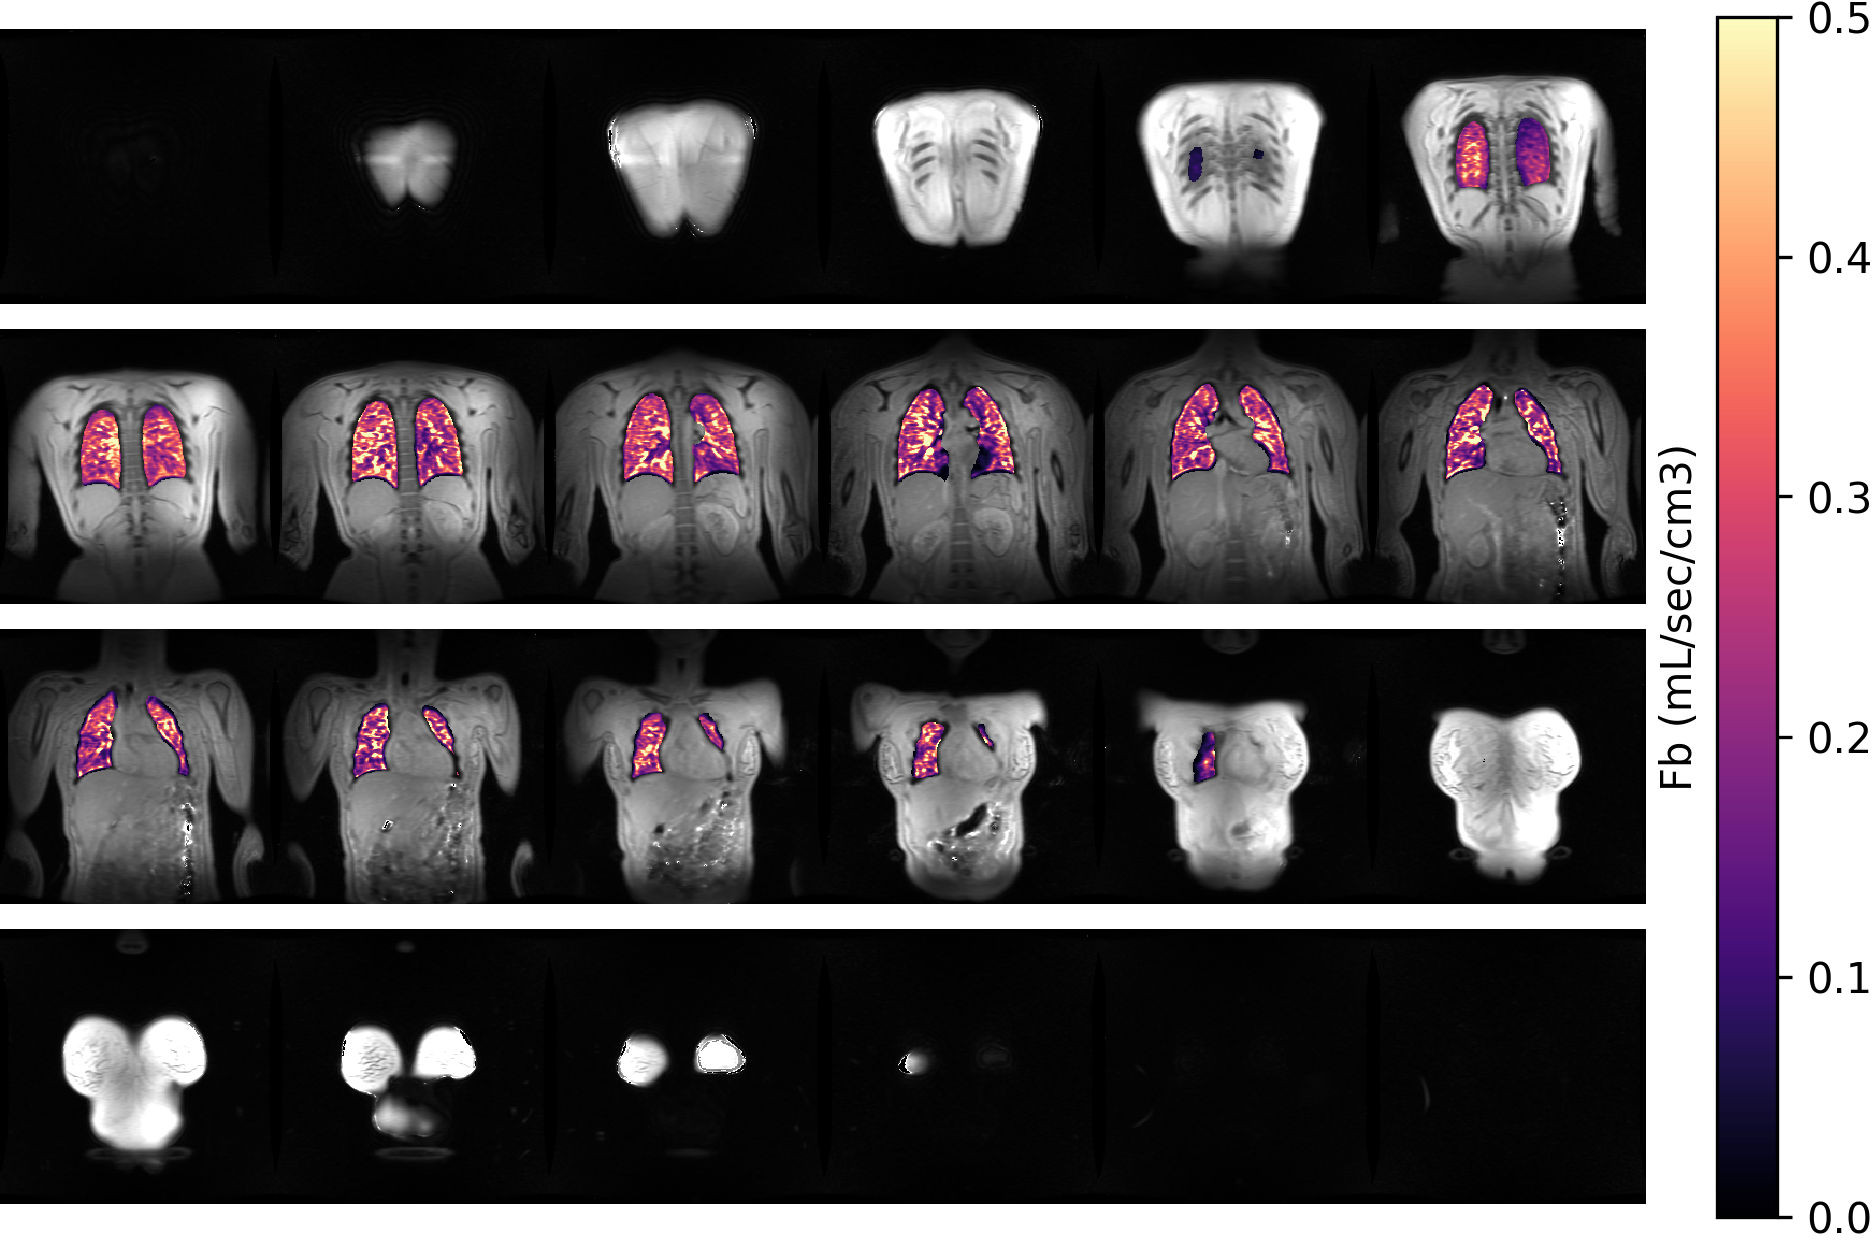

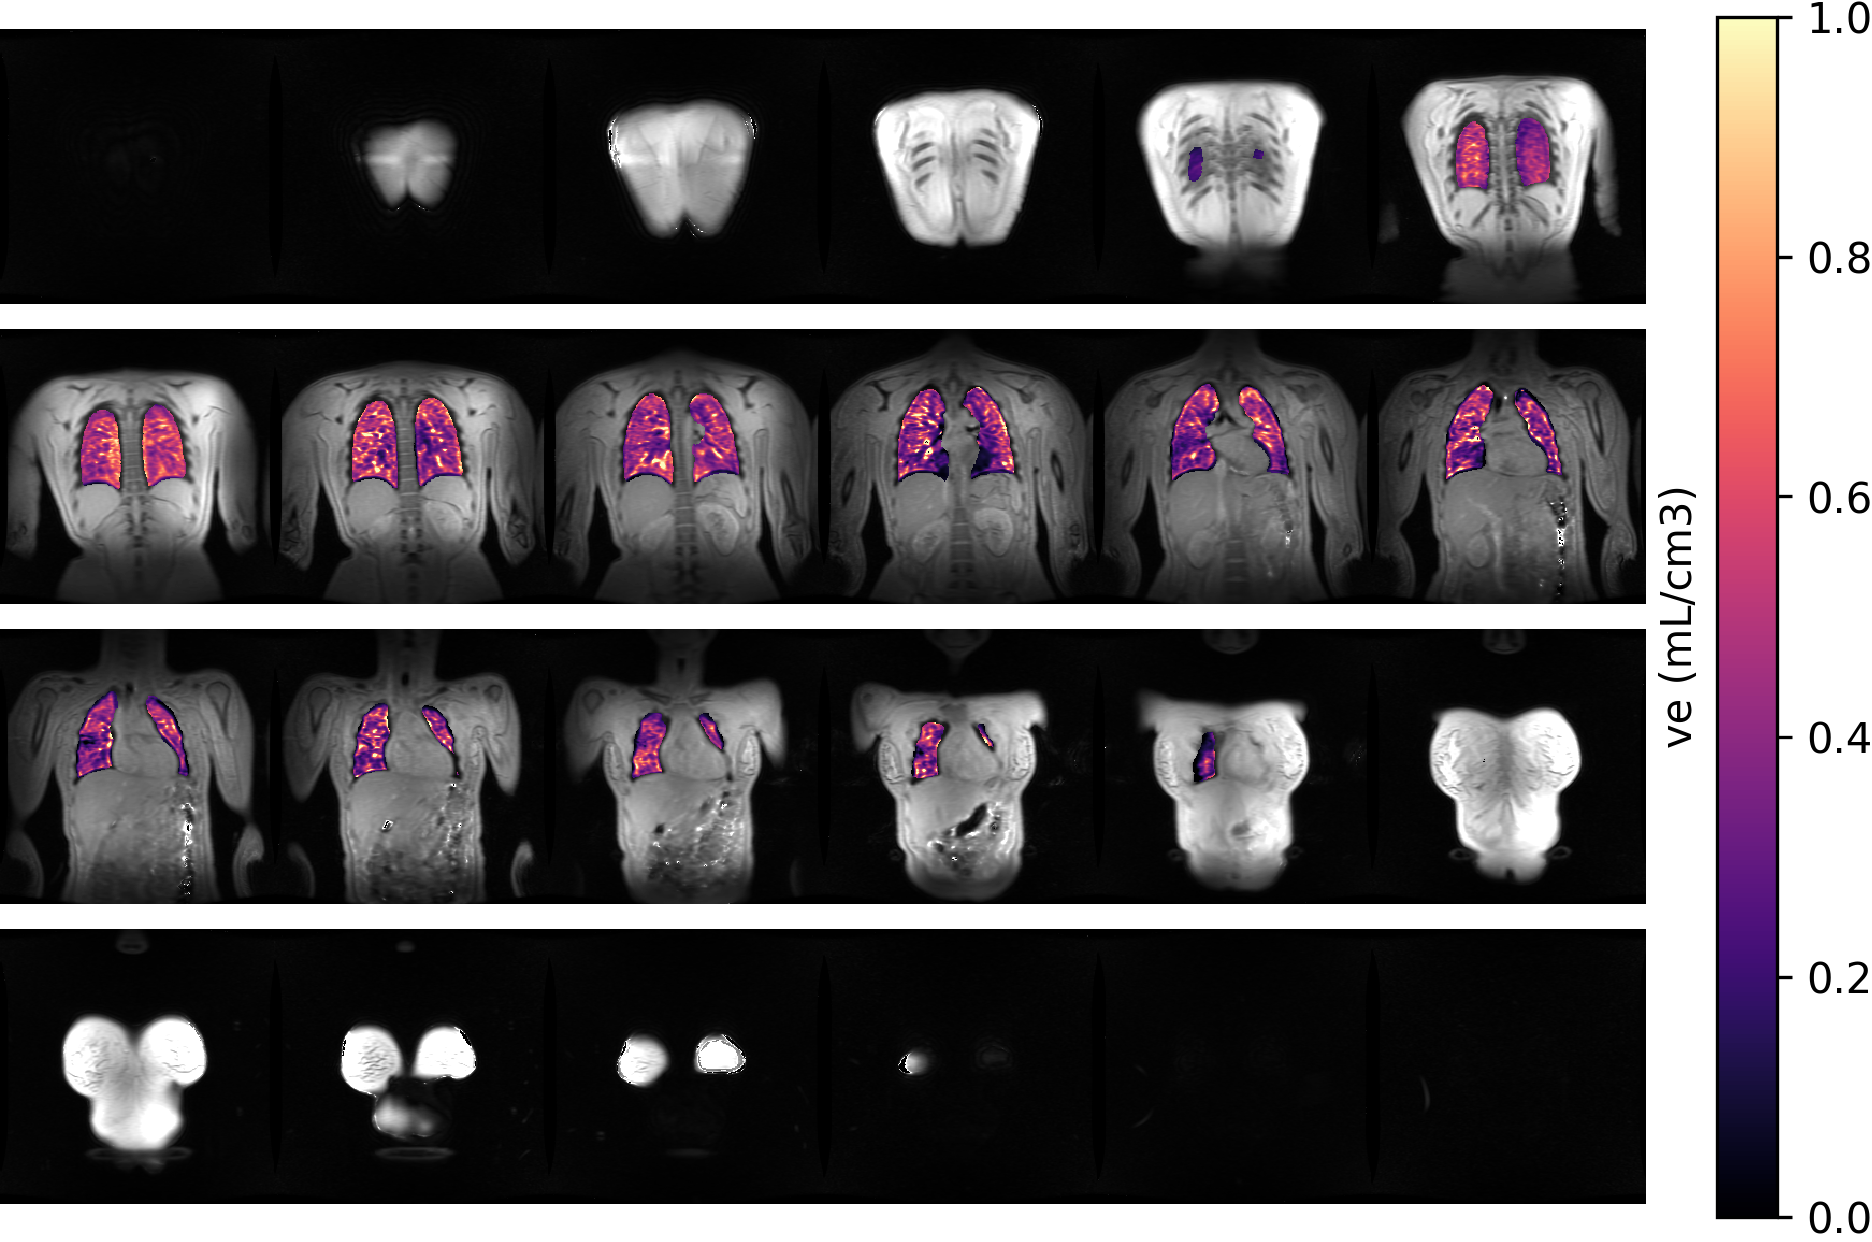

In [10]:
from case_studies.lung_dce import view_png

png = os.path.join(IMAGEPATH, f'Fb_model_free.png')
view_png(png)
png = os.path.join(IMAGEPATH, f've_model_free.png')
view_png(png)

Pixel-by-pixel model-based analysis

In [ ]:
from case_studies.lung_dce import pixel_analysis_model_based

pixel_analysis_model_based(MAPS, MASKS, IMAGEPATH, CHECKPOINTSPATH)

In [ ]:
from case_studies.lung_dce import view_png

png = os.path.join(IMAGEPATH, f'Fb_model_based.png')
view_png(png)
png = os.path.join(IMAGEPATH, f'vb_model_based.png')
view_png(png)

# Step 6: Export imaging biomarkers

In [ ]:
from case_studies.lung_dce import pixel_averages_model_based

pixel_averages_model_based(MAPS, MASKS, SUBJ, BUILD_PATH)